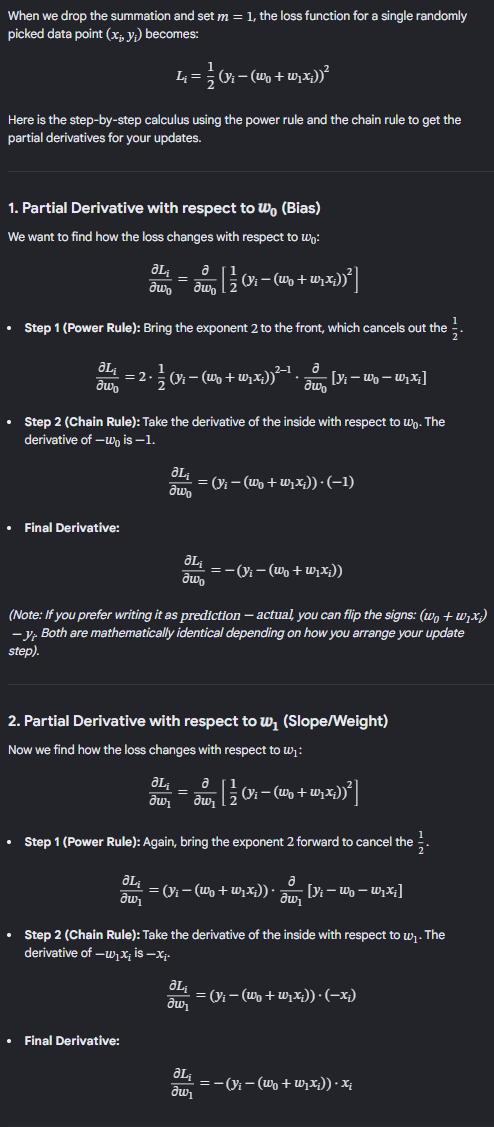

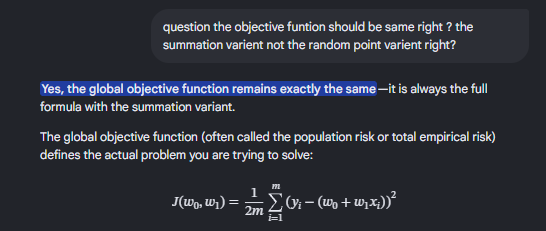

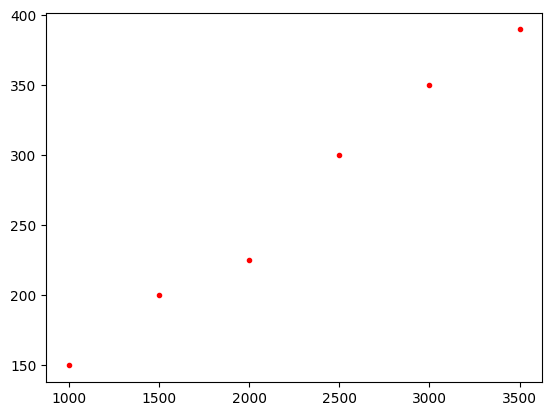

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import random

house_size = [1000, 1500, 2000, 2500, 3000, 3500]
house_price = [150, 200, 225, 300, 350, 390]

plt.scatter(house_size, house_price, marker = '.', color = 'red')
plt.show()

Current Knobs [46.3966471  98.05766225], Current Height: 45.04536221190282


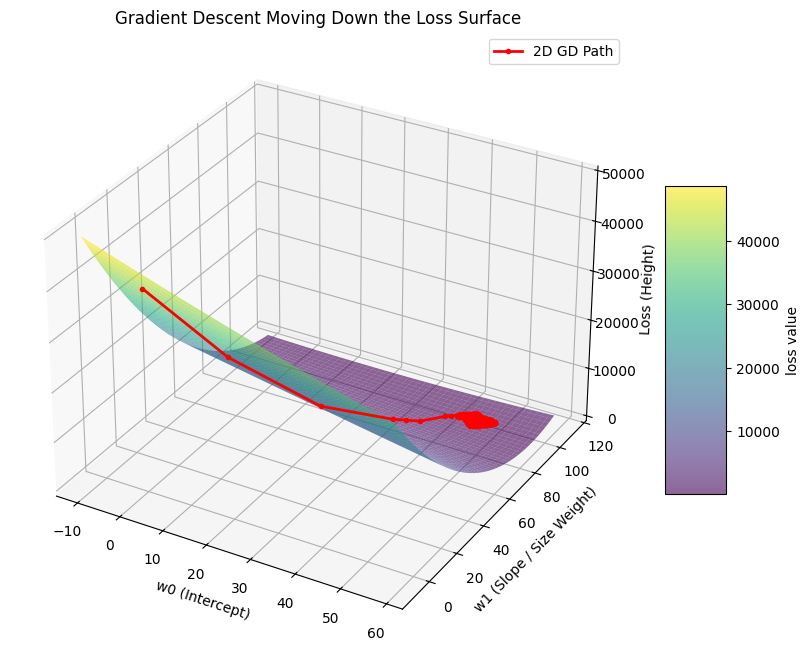

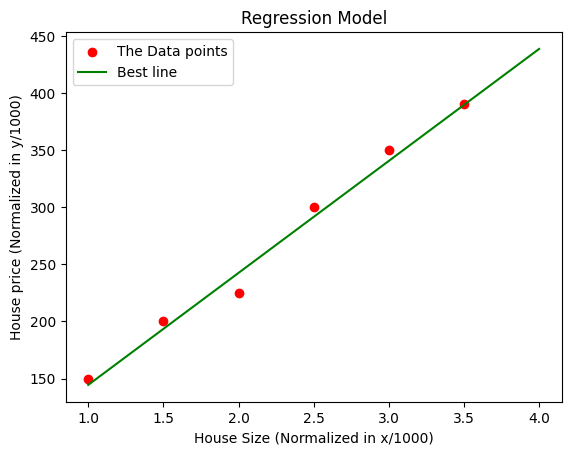

In [10]:
x = [i/1000 for i in house_size]
y = house_price

length = len(house_price)

w = [0.0,0.0] # w0,w1
tol = 1e-6
k = 0
max_iter = 1000
alpha = 0.05

#added the history tracking
history_of_w0 = [w[0]]
history_of_w1 = [w[1]]

def l(w0, w1, m):
    summation_of_error_square = 0
    for i in range(m):
        predicted_value = w0 + w1*x[i]
        real_value = y[i]

        error = (real_value - predicted_value)**2

        #add the error
        summation_of_error_square = summation_of_error_square + error
        Z = 1/(2*m) * summation_of_error_square 
    return Z

#found the z value
history_of_Z = [l(w[0], w[1], length)]

def stochastic_gradient(w0, w1):
    random_data_point_i = random.randint(0,length-1)
    partial_derivative_w0 = -(y[random_data_point_i]-(w0+w1*x[random_data_point_i]))
    partial_derivative_w1 = -(y[random_data_point_i]-(w0+w1*x[random_data_point_i]))*x[random_data_point_i]

    return np.array([partial_derivative_w0, partial_derivative_w1])

while max_iter>k:

    #direction:
    direction = -stochastic_gradient(w[0], w[1])

    new_pos = w + (alpha * direction)

    #update
    w= new_pos

    k +=1

    history_of_w0.append(w[0])
    history_of_w1.append(w[1])
    history_of_Z.append(l(w[0], w[1], length))

print(f'Current Knobs {w}, Current Height: {l(w[0], w[1], length)}')

#lets try plotting the GD in 3d:
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(projection='3d')



x_surf = np.linspace(min(history_of_w0)-10, max(history_of_w0)+10, 200)
y_surf = np.linspace(min(history_of_w1)-10,max(history_of_w1)+10,200)
X,Y = np.meshgrid(x_surf, y_surf)
Z = l(X, Y, length)


surf = ax.plot_surface(X,Y,Z,cmap='viridis', alpha=0.6) #the 3d land
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5, label='loss value')

ax.plot(history_of_w0, history_of_w1, history_of_Z,color='red', marker='.', 
    linewidth=2, label='2D GD Path', zorder=10)

ax.set_xlabel('w0 (Intercept)')
ax.set_ylabel('w1 (Slope / Size Weight)')
ax.set_zlabel('Loss (Height)')
ax.set_title('Gradient Descent Moving Down the Loss Surface')
ax.legend()
plt.show()


#plotting the line now:
plt.scatter(x,y, color = 'Red', marker ='o', label = 'The Data points')
plt.xlabel('House Size (Normalized in x/1000)')
plt.ylabel('House price (Normalized in y/1000)')
plt.title('Regression Model')

X = np.linspace(1, 4, 100)
Y = w[0] + w[1] * X
plt.plot(X,Y, label = 'Best line', color='Green')
plt.legend()
plt.show()

